# GIAI ĐOẠN 2: THỰC THI QUY TRÌNH KHAI PHÁ DỮ LIỆU (KDD PIPELINE)
## Bước 2.1: Tiền xử lý & Làm sạch dữ liệu tuyển dụng (Data Cleaning)

Notebook này thực hiện toàn diện các bước tiền xử lý dữ liệu trên tệp `raw_jobs_data.csv`:
1. **Khám phá dữ liệu thô & Xử lý trùng lặp**
2. **Xử lý mức lương (Salary Normalization):** Dùng Regex tách `Luong_Min`, `Luong_Max`, quy đổi đồng nhất về **Triệu VNĐ**, và gán nhãn chiến lược cho các tin *Thỏa thuận / Thương lượng / Cạnh tranh*.
3. **Chuẩn hóa địa điểm & Số năm kinh nghiệm:** Rút trích tỉnh/thành phố chuẩn (`Hà Nội`, `TP.HCM`, `Đà Nẵng`, `Remote`, ...) và chuẩn hóa kinh nghiệm thành biến số thực & phân nhóm.
4. **Xử lý chuỗi văn bản mô tả & Trích xuất đặc trưng kỹ năng (Text Preprocessing & Feature Extraction):** Làm sạch HTML tag, loại bỏ stop words Việt/Anh, trích xuất Skill Dictionary (5 nhóm kỹ năng) thành mảng kỹ năng và ma trận nhị phân (One-Hot Encoding).
5. **Trực quan hóa kiểm chứng & Xuất dữ liệu sạch.**

In [1]:
import re
import html
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
sns.set_theme(style="whitegrid")

# Đọc dữ liệu thô
df = pd.read_csv('raw_jobs_data.csv')
print(f"Kích thước dữ liệu ban đầu: {df.shape[0]} dòng, {df.shape[1]} cột")
print("\nCác cột hiện có:", df.columns.tolist())

# Kiểm tra và loại bỏ trùng lặp theo job_url (nếu có)
dup_count = df.duplicated(subset=['job_url']).sum()
print(f"Số dòng trùng lặp theo job_url: {dup_count}")
if dup_count > 0:
    df = df.drop_duplicates(subset=['job_url'], keep='first').reset_index(drop=True)
    print(f"Kích thước sau khi xóa trùng lặp: {df.shape}")

df.head(3)

Kích thước dữ liệu ban đầu: 944 dòng, 11 cột

Các cột hiện có: ['scraped_timestamp', 'source_platform', 'search_keyword', 'job_url', 'job_title', 'company_name', 'location', 'salary_raw', 'experience_required', 'job_description', 'requirements_and_benefits']
Số dòng trùng lặp theo job_url: 0


,scraped_timestamp,source_platform,search_keyword,job_url,job_title,company_name,location,salary_raw,experience_required,job_description,requirements_and_benefits
0,2026-11-20 10:58:13,VietnamWorks,AI Engineer,https://www.vietnamworks.com/senior-machine-le...,Senior Machine Learning & Industrial Data Spec...,Công Ty TNHH Mi-Jack Manufacturing Global Viet...,Ho Chi Minh,Negotiable,Senior,All locationsSearchCancelCommunityAll categori...,NaN
1,2026-11-20 10:58:18,VietnamWorks,AI Engineer,https://www.vietnamworks.com/senior-ai-enginee...,Senior AI Engineer (Computer Vision/NLP/LLM) -...,NGÂN HÀNG TMCP QUÂN ĐỘI – MBBANK,Hà Nội,Negotiable,Senior,All locationsSearchCancelCommunityAll categori...,NaN
2,2026-11-20 10:58:23,VietnamWorks,AI Engineer,https://www.vietnamworks.com/hotel-market-rese...,Hotel Market Research & Business Intelligence ...,Công ty TNHH Quản Lý Khách Sạn và Du Lịch VHG,đà nẵng,Negotiable,Fresher,All locationsSearchCancelCommunityAll categori...,NaN


---
## 1. Xử lý mức lương (Salary Normalization)

**Chiến lược xử lý:**
- **Quy đổi đơn vị:** Quy đổi toàn bộ về đơn vị **Triệu VNĐ** (tỷ giá tham chiếu `1 USD = 25,000 VNĐ`, tức `0.025 Triệu VNĐ`).
- **Xử lý định dạng số:** Phân biệt dấu `.` / `,` dùng làm dấu phân cách hàng nghìn (VD: `1.000 - 1.500 USD`, `2,500 USD`) và dấu thập phân (VD: `15,5 - 16,5 Triệu`, `1.5 - 2 triệu`).
- **Xử lý khoảng mở:**
  - `Từ X` / `Trên X`: gán `Luong_Min = X`, `Luong_Max = NaN`.
  - `Tới X` / `Up to X`: gán `Luong_Min = NaN`, `Luong_Max = X`.
- **Chiến lược với tin "Thỏa thuận / Thương lượng / Cạnh tranh / Negotiable":**
  - Giữ `Luong_Min = NaN`, `Luong_Max = NaN` (không điền 0 để tránh làm lệch trung bình/phân phối lương).
  - Tạo cột cờ nhị phân `La_Thoa_Thuan` (`1`: Thỏa thuận, `0`: Có mức lương cụ thể).

In [2]:
USD_TO_MILLION_VND = 25000 / 1_000_000  # 0.025 triệu VNĐ / 1 USD

def parse_number(num_str, is_usd=False):
    """Chuyển chuỗi số thành float, xử lý đúng dấu chấm/phẩy hàng nghìn và thập phân."""
    s = num_str.strip()
    if is_usd:
        # Với USD: 1,500 hoặc 1.500 đều là hàng nghìn
        if re.match(r'^\d{1,3}([.,]\d{3})+$', s):
            s = s.replace('.', '').replace(',', '')
        else:
            s = s.replace(',', '')
    else:
        # Với Triệu VNĐ: 15,5 hoặc 1.5 là số thập phân
        if re.match(r'^\d{1,3}([.,]\d{3})+$', s):
            s = s.replace('.', '').replace(',', '')
        else:
            s = s.replace(',', '.')
    return float(s)

def normalize_salary(raw_val):
    if pd.isna(raw_val):
        return pd.Series([np.nan, np.nan, np.nan, 1])
    
    text = str(raw_val).strip()
    text_lower = text.lower()
    
    # Kiểm tra các từ khóa thỏa thuận / cạnh tranh
    negotiable_keywords = ['thỏa thuận', 'thoả thuận', 'thương lượng', 'cạnh tranh', 'negotiable']
    if any(kw in text_lower for kw in negotiable_keywords):
        return pd.Series([np.nan, np.nan, np.nan, 1])
    
    # Xác định đơn vị tiền tệ
    is_usd = ('$' in text) or ('usd' in text_lower)
    
    # Trích xuất tất cả các con số trong chuỗi
    numbers = re.findall(r'\d+(?:[.,]\d+)*', text)
    if not numbers:
        return pd.Series([np.nan, np.nan, np.nan, 1])
    
    vals = [parse_number(n, is_usd=is_usd) for n in numbers]
    
    # Quy đổi về Triệu VNĐ
    if is_usd:
        vals = [round(v * USD_TO_MILLION_VND, 2) for v in vals]
    else:
        # Nếu giá trị ghi bằng VNĐ đầy đủ (ví dụ > 100000), chia 1,000,000
        vals = [round(v / 1_000_000, 2) if v > 1000 else round(v, 2) for v in vals]
    
    luong_min, luong_max = np.nan, np.nan
    
    if len(vals) >= 2:
        luong_min, luong_max = min(vals[0], vals[1]), max(vals[0], vals[1])
    elif len(vals) == 1:
        if any(kw in text_lower for kw in ['tới', 'đến', 'up to', 'max', 'dưới']):
            luong_max = vals[0]
        elif any(kw in text_lower for kw in ['từ', 'trên', 'from', 'min', 'over']):
            luong_min = vals[0]
        else:
            luong_min = luong_max = vals[0]
            
    # Tính lương trung bình đại diện
    if pd.notna(luong_min) and pd.notna(luong_max):
        luong_tb = round((luong_min + luong_max) / 2, 2)
    elif pd.notna(luong_min):
        luong_tb = luong_min
    else:
        luong_tb = luong_max
        
    return pd.Series([luong_min, luong_max, luong_tb, 0])

# Áp dụng hàm chuẩn hóa lương
df[['Luong_Min', 'Luong_Max', 'Luong_TB', 'La_Thoa_Thuan']] = df['salary_raw'].apply(normalize_salary)
df['La_Thoa_Thuan'] = df['La_Thoa_Thuan'].astype(int)

print("Thống kê tỷ lệ tin Thỏa thuận vs Có mức lương cụ thể:")
print(df['La_Thoa_Thuan'].value_counts().rename({1: 'Thỏa thuận (1)', 0: 'Có lương cụ thể (0)'}))

print("\nThống kê mô tả mức lương (Triệu VNĐ):")
print(df[['Luong_Min', 'Luong_Max', 'Luong_TB']].describe().round(2))

print("\nKiểm tra mẫu kết quả tách lương (các tin có lương):")
df[df['La_Thoa_Thuan'] == 0][['salary_raw', 'Luong_Min', 'Luong_Max', 'Luong_TB']].drop_duplicates().head(15)

Thống kê tỷ lệ tin Thỏa thuận vs Có mức lương cụ thể:
La_Thoa_Thuan
Thỏa thuận (1)         814
Có lương cụ thể (0)    130
Name: count, dtype: int64

Thống kê mô tả mức lương (Triệu VNĐ):
       Luong_Min  Luong_Max  Luong_TB
count     123.00     127.00    130.00
mean       17.38      28.09     23.01
std         9.15      15.20     12.62
min         1.00       2.00      1.75
25%        12.00      18.00     15.00
50%        15.00      25.00     21.25
75%        20.00      35.00     30.00
max        60.00      80.00     70.00

Kiểm tra mẫu kết quả tách lương (các tin có lương):


,salary_raw,Luong_Min,Luong_Max,Luong_TB
53,15 - 30 triệu,15.0,30.0,22.50
78,$1300 - $2000,32.5,50.0,41.25
209,30 - 50 Triệu,30.0,50.0,40.00
214,60-80 Triệu,60.0,80.0,70.00
252,20 - 35 triệu,20.0,35.0,27.50
253,15 - 30 Triệu,15.0,30.0,22.50
270,3-5 triệu,3.0,5.0,4.00
315,15 - 18 triệu,15.0,18.0,16.50
420,25 - 70 triệu,25.0,70.0,47.50
423,18 - 25 triệu,18.0,25.0,21.50


---
## 2. Chuẩn hóa Địa điểm & Số năm kinh nghiệm

- **Địa điểm (`Location_Chuan`):** Rút trích và chỉ giữ lại 4 địa điểm chuẩn theo yêu cầu: **`Hà Nội`**, **`TP.HCM`**, **`Đà Nẵng`**, **`Remote`**. Các tin tuyển dụng thuộc tỉnh/thành phố khác sẽ được loại bỏ để làm sạch tập dữ liệu.
- **Số năm kinh nghiệm (`Kinh_Nghiem_Nam` & `Nhom_Kinh_Nghiem`):**
  - Chuẩn hóa các nhãn phổ biến (`Fresher`, `Junior`, `Senior`, `3 năm`, `Trên 5 năm`, `Không yêu cầu`, `Dưới 1 năm`).
  - Với các dòng bị lẫn tên ngành nghề ở cột `experience_required`, tự động trích xuất bổ sung số năm kinh nghiệm từ nội dung `job_description` / `requirements_and_benefits` bằng Regex.

In [3]:
def normalize_location(loc):
    if pd.isna(loc):
        return None
    text = str(loc).lower().strip()
    
    if 'remote' in text or 'từ xa' in text or 'work from home' in text:
        return 'Remote'
    if any(k in text for k in ['hồ chí minh', 'ho chi minh', 'hcm', 'sài gòn', 'saigon', 'thủ đức']):
        return 'TP.HCM'
    if any(k in text for k in ['hà nội', 'ha noi', 'hanoi']):
        return 'Hà Nội'
    if any(k in text for k in ['đà nẵng', 'da nang', 'danang']):
        return 'Đà Nẵng'
    return None

df['Location_Chuan'] = df['location'].apply(normalize_location)

# Loại bỏ các tin thuộc tỉnh/thành phố khác (Location_Chuan bị None)
before_drop = len(df)
df = df.dropna(subset=['Location_Chuan']).reset_index(drop=True)
dropped_count = before_drop - len(df)

print(f"Đã loại bỏ {dropped_count} tin tuyển dụng thuộc các tỉnh/thành khác.")
print(f"Số lượng tin còn lại sau khi lọc địa điểm: {len(df)} dòng")
print("\nPhân bố địa điểm chuẩn hóa:")
print(df['Location_Chuan'].value_counts())

def extract_experience(row):
    exp_raw = str(row['experience_required']) if pd.notna(row['experience_required']) else ''
    exp_lower = exp_raw.lower().strip()
    
    # 1. Xử lý trực tiếp từ cột experience_required
    if 'không yêu cầu' in exp_lower or 'no experience' in exp_lower:
        return 0.0
    if 'dưới 1 năm' in exp_lower or 'intern' in exp_lower or 'thực tập' in exp_lower:
        return 0.5
    if exp_lower == 'fresher':
        return 0.5
    if exp_lower == 'junior':
        return 1.5
    if exp_lower == 'middle' or exp_lower == 'mid-level':
        return 3.0
    if exp_lower == 'senior':
        return 5.0
    if 'trên 5 năm' in exp_lower:
        return 5.5
    
    # Regex số năm trong experience_required (VD: "3 năm", "2 - 4 năm")
    m = re.findall(r'(\d+(?:\.\d+)?)\s*(?:-\s*(\d+(?:\.\d+)?)\s*)?(?:năm|year|yr)', exp_lower)
    if m:
        low = float(m[0][0])
        high = float(m[0][1]) if m[0][1] else low
        return round((low + high) / 2, 1)
    
    # 2. Fallback: tìm trong job_description nếu experience_required bị nhiễu (chứa tên ngành nghề)
    desc = (str(row['job_description']) + ' ' + str(row['requirements_and_benefits'])).lower()
    m_desc = re.search(r'(?:tối thiểu|ít nhất|từ|at least|minimum)?\s*(\d{1,2})\s*(?:[-–]\s*(\d{1,2})\s*)?(?:\+\s*)?(?:năm kinh nghiệm|years? of experience|years? experience)', desc)
    if m_desc:
        low = float(m_desc.group(1))
        high = float(m_desc.group(2)) if m_desc.group(2) else low
        if low <= 15 and high <= 20:
            return round((low + high) / 2, 1)
            
    return np.nan

def group_experience(years):
    if pd.isna(years):
        return 'Chưa rõ / Không yêu cầu'
    if years <= 1.0:
        return 'Intern / Fresher (0-1 năm)'
    elif years <= 2.5:
        return 'Junior (1-2 năm)'
    elif years <= 4.5:
        return 'Middle (3-4 năm)'
    else:
        return 'Senior (5+ năm)'

df['Kinh_Nghiem_Nam'] = df.apply(extract_experience, axis=1)
df['Nhom_Kinh_Nghiem'] = df['Kinh_Nghiem_Nam'].apply(group_experience)

print("\nPhân bố nhóm kinh nghiệm sau chuẩn hóa:")
print(df['Nhom_Kinh_Nghiem'].value_counts())

Đã loại bỏ 43 tin tuyển dụng thuộc các tỉnh/thành khác.
Số lượng tin còn lại sau khi lọc địa điểm: 901 dòng

Phân bố địa điểm chuẩn hóa:
Location_Chuan
Hà Nội     538
TP.HCM     337
Đà Nẵng     26
Name: count, dtype: int64

Phân bố nhóm kinh nghiệm sau chuẩn hóa:
Nhom_Kinh_Nghiem
Intern / Fresher (0-1 năm)    582
Senior (5+ năm)               110
Middle (3-4 năm)               78
Chưa rõ / Không yêu cầu        75
Junior (1-2 năm)               56
Name: count, dtype: int64


---
## 3. Xử lý chuỗi văn bản mô tả (Text Preprocessing & Feature Extraction)

Quy trình thực hiện:
1. Gộp `job_description` và `requirements_and_benefits` thành văn bản đầy đủ (`full_text`).
2. Làm sạch HTML tags, giải mã HTML entities, loại bỏ ký tự đặc biệt thừa, chuẩn hóa chữ thường (`clean_text`).
3. Loại bỏ Stop words tiếng Việt & tiếng Anh (`text_no_stopwords`).
4. Xây dựng **Skill Dictionary** gồm 5 nhóm kỹ năng: `Programming Languages`, `Frameworks & Libraries`, `Cloud & DevOps`, `Databases`, `Soft Skills`.
5. Trích xuất thành mảng kỹ năng (`Skills_List`), số lượng kỹ năng (`Skill_Count`) và **Ma trận nhị phân (One-Hot Encoding)** với tiền tố `skill_`.

In [4]:
# Danh sách Stop words tiếng Việt & tiếng Anh phổ biến trong tin tuyển dụng
VI_STOPWORDS = {
    'và', 'của', 'các', 'có', 'được', 'cho', 'trong', 'là', 'với', 'tại', 'từ', 'đến',
    'về', 'theo', 'trên', 'dưới', 'những', 'một', 'này', 'đó', 'khi', 'để', 'như', 'cũng',
    'hoặc', 'nhưng', 'nếu', 'thì', 'vì', 'do', 'bởi', 'qua', 'lại', 'ra', 'vào', 'lên',
    'xuống', 'không', 'chưa', 'đã', 'đang', 'sẽ', 'phải', 'cần', 'nên', 'việc',
    'làm', 'công', 'ty', 'ứng', 'viên', 'vị', 'trí', 'kinh', 'nghiệm', 'yêu', 'cầu', 'mô', 'tả', 'quyền', 'lợi'
}

EN_STOPWORDS = {
    'the', 'and', 'for', 'with', 'that', 'this', 'from', 'are', 'will', 'have', 'has',
    'you', 'your', 'our', 'their', 'they', 'we', 'can', 'not', 'but', 'all', 'any', 'more',
    'about', 'into', 'over', 'such', 'other', 'than', 'then', 'its', 'who', 'what', 'which',
    'when', 'where', 'how', 'job', 'work', 'working', 'experience', 'years', 'team', 'role',
    'company', 'requirements', 'description', 'responsibilities', 'skills', 'ability', 'strong'
}

ALL_STOPWORDS = VI_STOPWORDS.union(EN_STOPWORDS)

def clean_html_and_text(text):
    if pd.isna(text):
        return ''
    # Giải mã HTML entities và xóa HTML tags
    t = html.unescape(str(text))
    t = re.sub(r'<[^>]+>', ' ', t)
    # Xóa URL và email
    t = re.sub(r'http\S+|www\.\S+|\S+@\S+', ' ', t)
    # Chuẩn hóa chữ thường và khoảng trắng (giữ lại +, #, . cho C++, C#, .NET, Node.js)
    t = t.lower()
    t = re.sub(r'[^a-z0-9àáạảãâầấậẩẫăằắặẳẵèéẹẻẽêềếệểễìíịỉĩòóọỏõôồốộổỗơờớợởỡùúụủũưừứựửữỳýỵỷỹđ+#.\s]', ' ', t)
    t = re.sub(r'\s+', ' ', t).strip()
    return t

def remove_stopwords(text):
    tokens = text.split()
    filtered = [tok for tok in tokens if tok not in ALL_STOPWORDS and len(tok) > 1]
    return ' '.join(filtered)

# Gộp và làm sạch văn bản
df['full_text'] = df['job_title'].fillna('') + ' ' + df['job_description'].fillna('') + ' ' + df['requirements_and_benefits'].fillna('')
df['clean_text'] = df['full_text'].apply(clean_html_and_text)
df['text_no_stopwords'] = df['clean_text'].apply(remove_stopwords)

# Từ điển kỹ năng công nghệ (Skill Dictionary) chia theo 5 nhóm
SKILL_DICTIONARY = {
    'Programming_Languages': {
        'Python': r'\bpython\b',
        'SQL': r'\bsql\b',
        'Java': r'\bjava\b',
        'JavaScript': r'\b(?:javascript|js)\b',
        'TypeScript': r'\b(?:typescript|ts)\b',
        'C_CPP': r'(?:\bc\+\+|\bc/c\+\+|\bcpp\b)',
        'CSharp': r'(?:c#|csharp)',
        'R_Lang': r'\br\b(?:\s*(?:programming|language|studio|/python))|\bpython/r\b',
        'Go': r'\b(?:golang|go\s+language)\b',
        'Scala': r'\bscala\b',
        'PHP': r'\bphp\b',
    },
    'Frameworks_Libraries': {
        'PyTorch': r'\bpytorch\b',
        'TensorFlow': r'\btensorflow\b',
        'Scikit_Learn': r'\b(?:scikit-learn|sklearn|scikit learn)\b',
        'Spark': r'\b(?:spark|pyspark)\b',
        'FastAPI': r'\bfastapi\b',
        'Django': r'\bdjango\b',
        'Flask': r'\bflask\b',
        'React': r'\breact(?:js|\.js)?\b',
        'NodeJS': r'\bnode(?:js|\.js)?\b',
        'Spring': r'\bspring\s*(?:boot)?\b',
        'DotNet': r'(?:\.net|dotnet)',
        'PowerBI': r'\bpower\s*bi\b',
        'Tableau': r'\btableau\b',
        'Excel': r'\bexcel\b',
        'LLM_GenAI': r'\b(?:llm|llms|langchain|generative ai|genai|rag|transformer)\b',
    },
    'Cloud_DevOps': {
        'AWS': r'\b(?:aws|amazon web services)\b',
        'Azure': r'\bazure\b',
        'GCP': r'\b(?:gcp|google cloud)\b',
        'Docker': r'\bdocker\b',
        'Kubernetes': r'\b(?:kubernetes|k8s)\b',
        'Git': r'\b(?:git|github|gitlab)\b',
        'CICD': r'\b(?:ci/cd|cicd|jenkins)\b',
        'MLOps_MLflow': r'\b(?:mlops|mlflow|kubeflow)\b',
        'Kafka': r'\bkafka\b',
        'Airflow': r'\bairflow\b',
        'Linux': r'\blinux\b',
    },
    'Databases': {
        'PostgreSQL': r'\b(?:postgresql|postgres)\b',
        'MySQL': r'\bmysql\b',
        'MongoDB': r'\bmongodb\b',
        'SQL_Server': r'\b(?:sql server|mssql)\b',
        'Oracle': r'\boracle\b',
        'Redis': r'\bredis\b',
        'Elasticsearch': r'\belasticsearch\b',
        'Snowflake_BigQuery': r'\b(?:snowflake|bigquery|databricks)\b',
    },
    'Soft_Skills': {
        'English': r'\b(?:english|tiếng anh|ielts|toeic)\b',
        'Communication': r'\b(?:communication|giao tiếp)\b',
        'Teamwork': r'\b(?:teamwork|làm việc nhóm|cross-functional)\b',
        'Problem_Solving': r'\b(?:problem[-\s]solving|giải quyết vấn đề)\b',
        'Analytical_Thinking': r'\b(?:analytical|tư duy phân tích|critical thinking)\b',
        'Leadership': r'\b(?:leadership|lãnh đạo|quản lý nhóm)\b',
        'Agile_Scrum': r'\b(?:agile|scrum)\b',
    }
}

# Trích xuất ma trận nhị phân (One-Hot Encoding) và mảng kỹ năng
all_skill_cols = []
for category, skills in SKILL_DICTIONARY.items():
    for skill_name, pattern in skills.items():
        col_name = f'skill_{skill_name}'
        df[col_name] = df['clean_text'].str.contains(pattern, regex=True, na=False).astype(int)
        all_skill_cols.append(col_name)

# Tạo cột mảng kỹ năng và tổng số kỹ năng
skill_names_clean = [c.replace('skill_', '') for c in all_skill_cols]
df['Skills_List'] = df[all_skill_cols].apply(
    lambda row: [name for name, val in zip(skill_names_clean, row) if val == 1], axis=1
)
df['Skill_Count'] = df[all_skill_cols].sum(axis=1)

print(f"Đã trích xuất thành công {len(all_skill_cols)} cột kỹ năng (One-Hot Encoding).")
print("Số kỹ năng trung bình trên mỗi tin tuyển dụng:", round(df['Skill_Count'].mean(), 2))
df[['job_title', 'Location_Chuan', 'Luong_Min', 'Luong_Max', 'Nhom_Kinh_Nghiem', 'Skill_Count', 'Skills_List']].head(5)

Đã trích xuất thành công 52 cột kỹ năng (One-Hot Encoding).
Số kỹ năng trung bình trên mỗi tin tuyển dụng: 3.27


,job_title,Location_Chuan,Luong_Min,Luong_Max,Nhom_Kinh_Nghiem,Skill_Count,Skills_List
0,Senior Machine Learning & Industrial Data Spec...,TP.HCM,NaN,NaN,Senior (5+ năm),8,"[PyTorch, TensorFlow, Scikit_Learn, Spark, Azu..."
1,Senior AI Engineer (Computer Vision/NLP/LLM) -...,Hà Nội,NaN,NaN,Senior (5+ năm),11,"[Python, C_CPP, PyTorch, TensorFlow, FastAPI, ..."
2,Hotel Market Research & Business Intelligence ...,Đà Nẵng,NaN,NaN,Intern / Fresher (0-1 năm),4,"[PowerBI, Excel, English, Analytical_Thinking]"
3,Senior Business Intelligence Associate (Operat...,TP.HCM,NaN,NaN,Senior (5+ năm),5,"[Python, Excel, English, Communication, Analyt..."
4,Phó phòng Công nghệ Mô hình - Deputy Head of M...,Hà Nội,NaN,NaN,Intern / Fresher (0-1 năm),3,"[Python, FastAPI, MLOps_MLflow]"


---
## 4. Trực quan hóa kiểm chứng kết quả làm sạch & Xuất dữ liệu

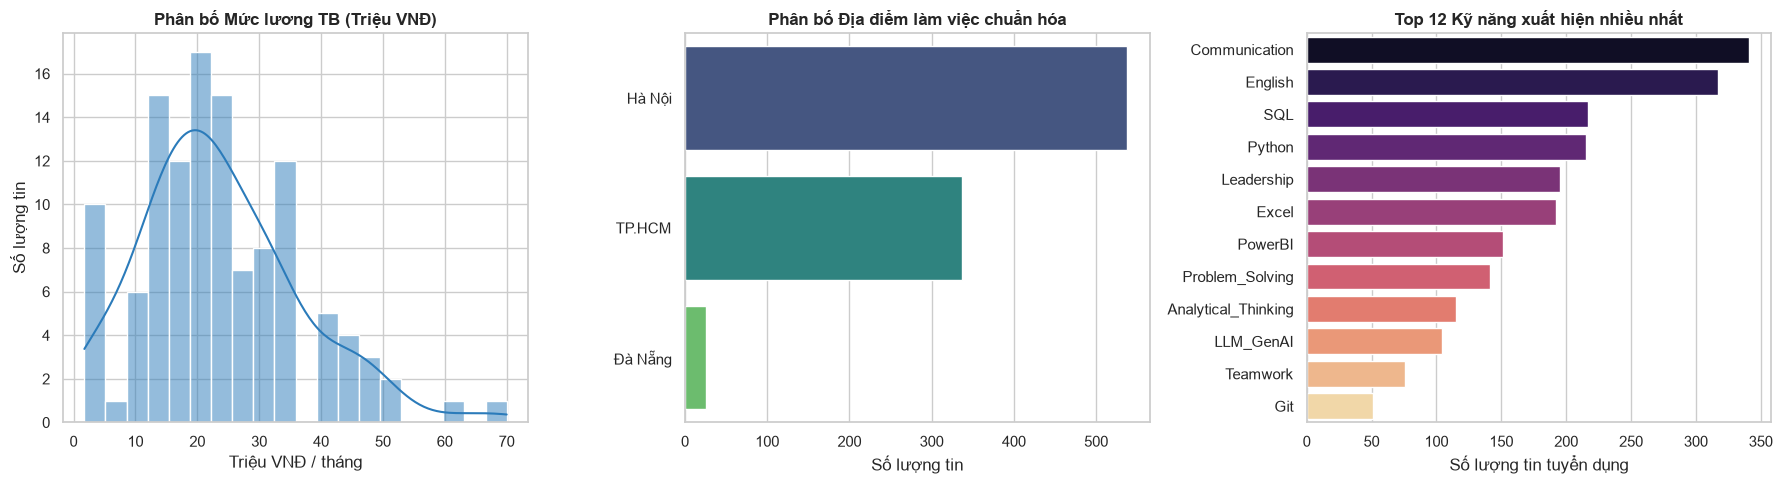

Đã lưu tệp dữ liệu sạch: cleaned_jobs_data.csv (901 dòng, 75 cột)


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Phân bố mức lương trung bình (các tin có lương)
sal_data = df[df['La_Thoa_Thuan'] == 0]['Luong_TB'].dropna()
sns.histplot(sal_data, bins=20, kde=True, color='#2b7bba', ax=axes[0])
axes[0].set_title('Phân bố Mức lương TB (Triệu VNĐ)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Triệu VNĐ / tháng')
axes[0].set_ylabel('Số lượng tin')

# 2. Top địa điểm tuyển dụng
loc_counts = df['Location_Chuan'].value_counts().head(6)
sns.barplot(x=loc_counts.values, y=loc_counts.index, palette='viridis', ax=axes[1])
axes[1].set_title('Phân bố Địa điểm làm việc chuẩn hóa', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Số lượng tin')
axes[1].set_ylabel('')

# 3. Top 12 kỹ năng phổ biến nhất
top_skills = df[all_skill_cols].sum().sort_values(ascending=False).head(12)
top_skills.index = [idx.replace('skill_', '') for idx in top_skills.index]
sns.barplot(x=top_skills.values, y=top_skills.index, palette='magma', ax=axes[2])
axes[2].set_title('Top 12 Kỹ năng xuất hiện nhiều nhất', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Số lượng tin tuyển dụng')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

cols_to_drop = ['job_description']
df = df.drop(columns=cols_to_drop, errors='ignore')
# Xuất tệp dữ liệu đã làm sạch để phục vụ các bước tiếp theo (EDA, Modeling, Clustering)
output_csv = 'cleaned_jobs_data.csv'
df.to_csv(output_csv, index=False, encoding='utf-8-sig')
print(f"Đã lưu tệp dữ liệu sạch: {output_csv} ({df.shape[0]} dòng, {df.shape[1]} cột)")